In [1]:
# Install missing libraries on RunPod
import subprocess
subprocess.run(['pip', 'install', '-q', 'seaborn', 'scikit-learn'], check=True)
print('Dependencies ready.')

Dependencies ready.


# 22b - Ablation Study: LSTM on WLASL-300

**Ablation Study** — identical training setup as Notebook 17b, but replacing
the GRU recurrent layer with an LSTM.

## Architecture: PoseClassifierLSTM
- Input projection: Linear → LayerNorm → ReLU → Dropout
- **LSTM** (bidirectional, 2 layers, hidden=256) — replaces GRU
- Temporal Attention (unchanged from Nb 17x)
- Classifier head (unchanged from Nb 17x)

## How to run
Run all cells in order. Expected Top-1 for 300 classes: ~25-35%.

In [2]:
# === Imports and Configuration ===
# ⬇️  Only this line changes between notebooks 22a / 22b / 22c / ...
SUBSET_PATH = "/workspace/dataset/subsets/wlasl_300_subset.json"
# ════════════════════════════════════════════════════════════════

import numpy as np
import json
import random
import time
from pathlib import Path
from datetime import datetime
from collections import Counter
from typing import Dict, List, Optional, Tuple

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

SUBSET_PATH = Path(SUBSET_PATH)
LANDMARKS_ROOT = Path("/workspace/dataset/wlasl2000")
EXPERIMENTS_BASE = Path("/workspace/experiments")

with open(SUBSET_PATH) as f:
    subset_meta = json.load(f)

EXPERIMENT_NAME = subset_meta['name']
NUM_CLASSES = subset_meta['num_classes']
OUTPUT_DIR = EXPERIMENTS_BASE / f"{EXPERIMENT_NAME}_lstm"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if NUM_CLASSES >= 800:
    _epochs   = 250
    _patience = 50
else:
    _epochs   = 150
    _patience = 30

CONFIG = {
    'max_frames':      64,
    'input_size':      63,
    'num_classes':     NUM_CLASSES,
    'hidden_size':     256,
    'num_layers':      2,
    'dropout':         0.4,
    'bidirectional':   True,
    'batch_size':      128,
    'epochs':          _epochs,
    'lr':              1e-3,
    'weight_decay':    5e-4,
    'label_smoothing': 0.1,
    'patience':        _patience,
}

print(f'Date:        {datetime.now().strftime("%Y-%m-%d %H:%M")}')
print(f'Device:      {device}')
print(f'Subset:      {EXPERIMENT_NAME}')
print(f'Classes:     {NUM_CLASSES}')
print(f'Output dir:  {OUTPUT_DIR}')
print(f'Epochs:      {CONFIG["epochs"]}  (patience={CONFIG["patience"]})')
print(f'')
stats = subset_meta['statistics']
print(f'Dataset stats:')
print(f'  Train: {stats["train"]}')
print(f'  Val:   {stats["val"]}')
print(f'  Test:  {stats["test"]}')
print(f'  Total: {stats["total"]}')
print(f'  Mean videos/class: {stats["mean_videos_per_class"]}')
print(f'  Class imbalance (CV): {stats["cv_pct"]}%')
print(f'  Classes with no val:  {stats["classes_with_no_val"]}')

Date:        2026-03-20 13:20
Device:      cuda
Subset:      wlasl_300
Classes:     300
Output dir:  /workspace/experiments/wlasl_300_lstm
Epochs:      150  (patience=30)

Dataset stats:
  Train: 1974
  Val:   474
  Test:  360
  Total: 2808
  Mean videos/class: 9.36
  Class imbalance (CV): 16.8%
  Classes with no val:  24


In [3]:
# === Dataset and DataLoaders ===

class SkeletalAugmentation:
    def __init__(self, rotation=10, scale=(0.9, 1.1), translation=0.1, noise=0.01, p=0.5):
        self.rotation = rotation
        self.scale = scale
        self.translation = translation
        self.noise = noise
        self.p = p

    def __call__(self, landmarks: np.ndarray) -> np.ndarray:
        landmarks = landmarks.copy()
        if random.random() < self.p:
            angle = np.radians(random.uniform(-self.rotation, self.rotation))
            cos_a, sin_a = np.cos(angle), np.sin(angle)
            x, y = landmarks[:, :, 0].copy(), landmarks[:, :, 1].copy()
            landmarks[:, :, 0] = x * cos_a - y * sin_a
            landmarks[:, :, 1] = x * sin_a + y * cos_a
        if random.random() < self.p:
            landmarks *= random.uniform(*self.scale)
        if random.random() < self.p:
            landmarks[:, :, 0] += random.uniform(-self.translation, self.translation)
            landmarks[:, :, 1] += random.uniform(-self.translation, self.translation)
        if random.random() < self.p:
            landmarks += np.random.normal(0, self.noise, landmarks.shape)
        return landmarks


class SubsetDataset(Dataset):
    def __init__(self, samples, landmarks_root, max_frames=64, augmentation=None):
        self.samples = samples
        self.root = landmarks_root
        self.max_frames = max_frames
        self.augmentation = augmentation

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        item = self.samples[idx]
        landmarks = np.load(self.root / item['path'])
        landmarks = self._pad_or_truncate(landmarks)
        if self.augmentation:
            landmarks = self.augmentation(landmarks)
        x = torch.tensor(landmarks.reshape(self.max_frames, -1), dtype=torch.float32)
        return x, item['gloss_idx']

    def _pad_or_truncate(self, lm):
        T = lm.shape[0]
        if T > self.max_frames:
            idx = np.linspace(0, T - 1, self.max_frames, dtype=int)
            return lm[idx]
        if T < self.max_frames:
            pad = np.zeros((self.max_frames - T, 21, 3))
            return np.concatenate([lm, pad], axis=0)
        return lm


aug = SkeletalAugmentation()
train_ds = SubsetDataset(subset_meta['samples']['train'], LANDMARKS_ROOT, CONFIG['max_frames'], augmentation=aug)
val_ds   = SubsetDataset(subset_meta['samples']['val'],   LANDMARKS_ROOT, CONFIG['max_frames'])
test_ds  = SubsetDataset(subset_meta['samples']['test'],  LANDMARKS_ROOT, CONFIG['max_frames'])

train_loader = DataLoader(train_ds, batch_size=CONFIG['batch_size'], shuffle=True,  num_workers=8, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=CONFIG['batch_size'], shuffle=False, num_workers=8)
test_loader  = DataLoader(test_ds,  batch_size=CONFIG['batch_size'], shuffle=False, num_workers=8)

print(f'Train: {len(train_ds):>6} samples  ({len(train_loader)} batches)')
print(f'Val:   {len(val_ds):>6} samples  ({len(val_loader)} batches)')
print(f'Test:  {len(test_ds):>6} samples  ({len(test_loader)} batches)')
all_labels = [item['gloss_idx'] for item in subset_meta['samples']['train']]
print(f'\nLabel range: [{min(all_labels)}, {max(all_labels)}]  (expected [0, {NUM_CLASSES - 1}])')
print(f'Unique labels in train: {len(set(all_labels))} / {NUM_CLASSES}')

Train:   1974 samples  (16 batches)
Val:      474 samples  (4 batches)
Test:     360 samples  (3 batches)

Label range: [0, 299]  (expected [0, 299])
Unique labels in train: 300 / 300


In [4]:
# === Model: PoseClassifierLSTM ===

class TemporalAttention(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.attention = nn.Sequential(
            nn.Linear(hidden_size, hidden_size // 2),
            nn.Tanh(),
            nn.Linear(hidden_size // 2, 1, bias=False),
        )

    def forward(self, rnn_out):
        scores  = self.attention(rnn_out).squeeze(-1)
        weights = F.softmax(scores, dim=1)
        context = torch.bmm(weights.unsqueeze(1), rnn_out).squeeze(1)
        return context, weights


class PoseClassifierLSTM(nn.Module):
    def __init__(self, config):
        super().__init__()
        input_size  = config['input_size']
        hidden_size = config['hidden_size']
        num_layers  = config['num_layers']
        num_classes = config['num_classes']
        dropout     = config['dropout']
        bidir       = config.get('bidirectional', True)
        rnn_hidden  = hidden_size * (2 if bidir else 1)

        self.input_projection = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.LayerNorm(hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.lstm = nn.LSTM(
            input_size=hidden_size, hidden_size=hidden_size,
            num_layers=num_layers, batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=bidir,
        )
        self.attention  = TemporalAttention(rnn_hidden)
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(rnn_hidden, hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, num_classes),
        )

    def forward(self, x, return_attention=False):
        x = self.input_projection(x)
        rnn_out, _ = self.lstm(x)  # _ discards (h_n, c_n)
        context, attn_w = self.attention(rnn_out)
        logits = self.classifier(context)
        return (logits, attn_w) if return_attention else logits


model = PoseClassifierLSTM(CONFIG).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f'Model: PoseClassifierLSTM')
print(f'Parameters: {n_params:,}')
print(f'Classes: {NUM_CLASSES}')

Model: PoseClassifierLSTM
Parameters: 2,986,540
Classes: 300


In [5]:
# === Training and Evaluation Functions ===

def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out  = model(x)
        loss = criterion(out, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total_loss += loss.item() * x.size(0)
        correct    += out.argmax(1).eq(y).sum().item()
        total      += x.size(0)
    return total_loss / total, 100 * correct / total


@torch.no_grad()
def evaluate(model, loader, top_k=(1, 5)):
    model.eval()
    total = 0
    topk_correct = {k: 0 for k in top_k}
    all_preds, all_labels = [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total += y.size(0)
        _, pred_topk = logits.topk(max(top_k), 1, True, True)
        for k in top_k:
            hit = pred_topk[:, :k].eq(y.view(-1, 1).expand_as(pred_topk[:, :k]))
            topk_correct[k] += hit.any(dim=1).sum().item()
        all_preds.extend(logits.argmax(1).cpu().numpy())
        all_labels.extend(y.cpu().numpy())
    metrics = {f'top{k}_acc': 100.0 * topk_correct[k] / total for k in top_k}
    return metrics, np.array(all_preds), np.array(all_labels)


print('Training functions defined.')

Training functions defined.


In [6]:
# === Training Loop ===

criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG['label_smoothing'])
optimizer = AdamW(model.parameters(), lr=CONFIG['lr'], weight_decay=CONFIG['weight_decay'])
scheduler = CosineAnnealingLR(optimizer, T_max=CONFIG['epochs'])

history = {'train_loss': [], 'train_acc': [], 'val_top1': [], 'val_top5': []}
best_val_top1    = 0.0
best_epoch       = 0
patience_counter = 0
train_start      = time.time()
CHECKPOINT_PATH  = OUTPUT_DIR / 'best_model.pt'

print(f'Training {EXPERIMENT_NAME}_lstm for up to {CONFIG["epochs"]} epochs (patience={CONFIG["patience"]})')
print(f'Checkpoint: {CHECKPOINT_PATH}')
print('=' * 65)

for epoch in range(CONFIG['epochs']):
    t0 = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer)
    val_metrics, _, _     = evaluate(model, val_loader)
    scheduler.step()

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_top1'].append(val_metrics['top1_acc'])
    history['val_top5'].append(val_metrics['top5_acc'])

    if val_metrics['top1_acc'] > best_val_top1:
        best_val_top1    = val_metrics['top1_acc']
        best_epoch       = epoch + 1
        patience_counter = 0
        torch.save({
            'epoch': epoch, 'model_state_dict': model.state_dict(),
            'val_top1': best_val_top1, 'config': CONFIG,
            'subset': EXPERIMENT_NAME, 'architecture': 'PoseClassifierLSTM',
        }, CHECKPOINT_PATH)
    else:
        patience_counter += 1

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f'Ep {epoch+1:3d}/{CONFIG["epochs"]} | Loss {train_loss:.3f} | Train {train_acc:.1f}% | '
              f'Val {val_metrics["top1_acc"]:.1f}% (Top-5 {val_metrics["top5_acc"]:.1f}%) | '
              f'Best {best_val_top1:.1f}% | {time.time()-t0:.1f}s')

    if patience_counter >= CONFIG['patience']:
        print(f'\nEarly stopping at epoch {epoch + 1}')
        break

elapsed = time.time() - train_start
print(f'\nTraining finished in {elapsed/60:.1f} min')
print(f'Best Val Top-1: {best_val_top1:.1f}% (epoch {best_epoch})')

Training wlasl_300_lstm for up to 150 epochs (patience=30)
Checkpoint: /workspace/experiments/wlasl_300_lstm/best_model.pt
Ep   1/150 | Loss 5.707 | Train 0.5% | Val 0.8% (Top-5 4.0%) | Best 0.8% | 3.4s
Ep  10/150 | Loss 4.428 | Train 9.6% | Val 7.6% (Top-5 24.1%) | Best 7.6% | 2.9s
Ep  20/150 | Loss 3.303 | Train 33.4% | Val 17.7% (Top-5 43.2%) | Best 17.7% | 3.0s
Ep  30/150 | Loss 2.495 | Train 55.8% | Val 20.9% (Top-5 48.5%) | Best 20.9% | 2.7s
Ep  40/150 | Loss 1.974 | Train 74.5% | Val 24.3% (Top-5 55.9%) | Best 24.9% | 2.7s
Ep  50/150 | Loss 1.670 | Train 86.7% | Val 25.5% (Top-5 53.6%) | Best 27.0% | 2.8s
Ep  60/150 | Loss 1.495 | Train 91.2% | Val 26.4% (Top-5 53.6%) | Best 27.6% | 2.8s
Ep  70/150 | Loss 1.376 | Train 95.4% | Val 28.1% (Top-5 53.2%) | Best 29.5% | 4.6s
Ep  80/150 | Loss 1.289 | Train 97.1% | Val 27.6% (Top-5 54.6%) | Best 29.5% | 2.6s
Ep  90/150 | Loss 1.253 | Train 97.2% | Val 30.4% (Top-5 52.5%) | Best 30.4% | 2.8s
Ep 100/150 | Loss 1.204 | Train 98.0% | Val 

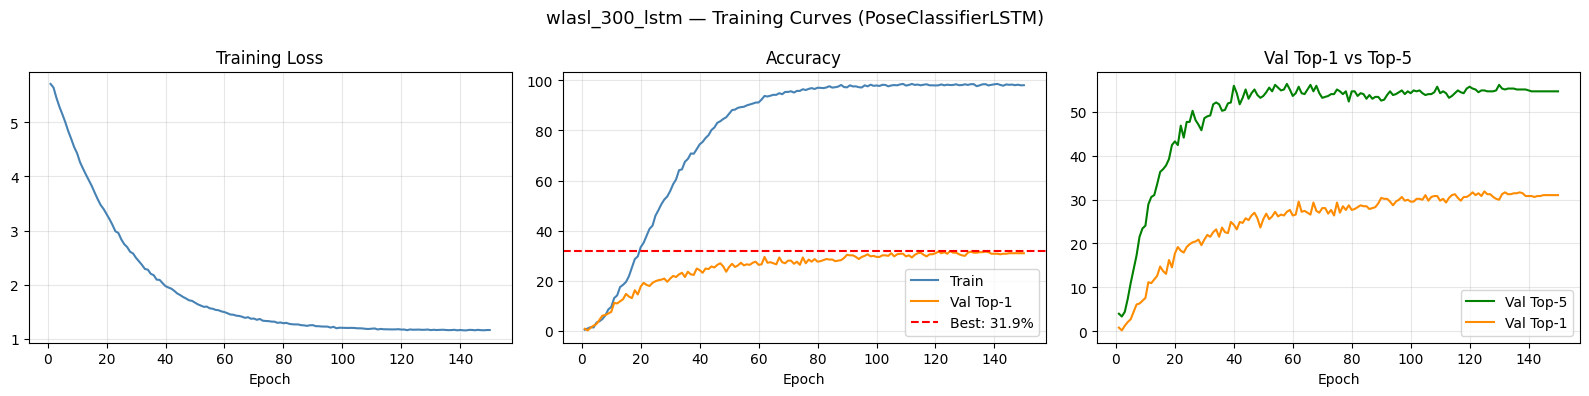

In [7]:
# === Training Curves ===

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
epochs_ran = range(1, len(history['train_loss']) + 1)

axes[0].plot(epochs_ran, history['train_loss'], color='steelblue')
axes[0].set_title('Training Loss'); axes[0].set_xlabel('Epoch'); axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_ran, history['train_acc'], label='Train', color='steelblue')
axes[1].plot(epochs_ran, history['val_top1'], label='Val Top-1', color='darkorange')
axes[1].axhline(best_val_top1, color='red', linestyle='--', label=f'Best: {best_val_top1:.1f}%')
axes[1].set_title('Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

axes[2].plot(epochs_ran, history['val_top5'], color='green', label='Val Top-5')
axes[2].plot(epochs_ran, history['val_top1'], color='darkorange', label='Val Top-1')
axes[2].set_title('Val Top-1 vs Top-5'); axes[2].set_xlabel('Epoch'); axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.suptitle(f'{EXPERIMENT_NAME}_lstm — Training Curves (PoseClassifierLSTM)', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# === Final Evaluation (val + test) ===

ckpt = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state_dict'])
print(f'Loaded best checkpoint (epoch {ckpt["epoch"] + 1}, val_top1={ckpt["val_top1"]:.1f}%)')

val_metrics,  val_preds,  val_labels  = evaluate(model, val_loader)
test_metrics, test_preds, test_labels = evaluate(model, test_loader)

print()
print('=' * 55)
print(f'RESULTS: {EXPERIMENT_NAME}_lstm  (PoseClassifierLSTM)')
print('=' * 55)
print(f'{"Split":<8} {"Top-1":>8} {"Top-5":>8} {"Samples":>9}')
print('-' * 35)
print(f'{"Val":<8} {val_metrics["top1_acc"]:>7.1f}% {val_metrics["top5_acc"]:>7.1f}% {len(val_ds):>9}')
print(f'{"Test":<8} {test_metrics["top1_acc"]:>7.1f}% {test_metrics["top5_acc"]:>7.1f}% {len(test_ds):>9}')
print('=' * 55)

Loaded best checkpoint (epoch 125, val_top1=31.9%)

RESULTS: wlasl_300_lstm  (PoseClassifierLSTM)
Split       Top-1    Top-5   Samples
-----------------------------------
Val         31.9%    54.9%       474
Test        27.2%    54.4%       360


In [9]:
# === Per-Class Accuracy Analysis ===

idx_to_gloss = subset_meta['idx_to_gloss']
per_class_acc = {}
for cls_idx in range(NUM_CLASSES):
    mask = test_labels == cls_idx
    if mask.sum() == 0: continue
    acc = 100.0 * (test_preds[mask] == cls_idx).sum() / mask.sum()
    per_class_acc[cls_idx] = {'gloss': idx_to_gloss[str(cls_idx)], 'acc': float(acc), 'n_test': int(mask.sum())}

accs = [v['acc'] for v in per_class_acc.values()]
print(f'Per-class accuracy — Mean: {np.mean(accs):.1f}%  Median: {np.median(accs):.1f}%  Std: {np.std(accs):.1f}%')
print(f'100%: {sum(1 for a in accs if a==100)}   0%: {sum(1 for a in accs if a==0)}')

sorted_by_acc = sorted(per_class_acc.items(), key=lambda x: x[1]['acc'])
print('\nTop 10:')
for _, info in sorted_by_acc[-10:][::-1]:
    print(f'  {info["gloss"]:<20} {info["acc"]:>6.1f}%  (n={info["n_test"]})')
print('\nBottom 10:')
for _, info in sorted_by_acc[:10]:
    print(f'  {info["gloss"]:<20} {info["acc"]:>6.1f}%  (n={info["n_test"]})')

Per-class accuracy — Mean: 27.4%  Median: 0.0%  Std: 39.8%
100%: 49   0%: 162

Top 10:
  yesterday             100.0%  (n=1)
  yes                   100.0%  (n=1)
  white                 100.0%  (n=1)
  vomit                 100.0%  (n=1)
  voice                 100.0%  (n=2)
  upset                 100.0%  (n=1)
  tell                  100.0%  (n=1)
  study                 100.0%  (n=1)
  stay                  100.0%  (n=1)
  snow                  100.0%  (n=1)

Bottom 10:
  accident                0.0%  (n=2)
  africa                  0.0%  (n=1)
  ago                     0.0%  (n=1)
  allow                   0.0%  (n=2)
  alone                   0.0%  (n=1)
  analyze                 0.0%  (n=1)
  arrive                  0.0%  (n=2)
  australia               0.0%  (n=1)
  awful                   0.0%  (n=1)
  baby                    0.0%  (n=2)


In [10]:
# === Top-20 Confused Pairs (confusion matrix skipped for > 100 classes) ===

print(f'Confusion matrix skipped for {NUM_CLASSES} classes. Top-20 most confused pairs:\n')
wrong_mask = test_preds != test_labels
pair_counts = Counter(zip(test_labels[wrong_mask].tolist(), test_preds[wrong_mask].tolist()))
print(f'{"True":<22} {"Predicted":<22} {"Count":>6}')
print('-' * 55)
for (true_idx, pred_idx), count in pair_counts.most_common(20):
    print(f'{idx_to_gloss.get(str(true_idx), str(true_idx)):<22} '
          f'{idx_to_gloss.get(str(pred_idx), str(pred_idx)):<22} {count:>6}')

Confusion matrix skipped for 300 classes. Top-20 most confused pairs:

True                   Predicted               Count
-------------------------------------------------------
beer                   brown                       2
dirty                  full                        2
exchange               trade                       2
meat                   all                         2
onion                  apple                       2
past                   before                      2
accident               idea                        1
accident               first                       1
add                    helicopter                  1
africa                 girl                        1
ago                    before                      1
allow                  fish                        1
allow                  walk                        1
alone                  tell                        1
analyze                ready                       1
appointment            mo

In [11]:
# === Save Results JSON ===

results = {
    'experiment': f'{EXPERIMENT_NAME}_lstm', 'architecture': 'PoseClassifierLSTM',
    'date': datetime.now().strftime('%Y-%m-%d %H:%M'), 'subset_path': str(SUBSET_PATH),
    'num_classes': NUM_CLASSES, 'config': CONFIG,
    'dataset': {'train': len(train_ds), 'val': len(val_ds), 'test': len(test_ds)},
    'training': {'best_val_top1': best_val_top1, 'best_epoch': best_epoch,
                 'total_epochs': len(history['train_acc']), 'training_time_s': round(elapsed, 1)},
    'val_metrics': val_metrics, 'test_metrics': test_metrics,
    'per_class_accuracy': {str(k): v for k, v in per_class_acc.items()},
    'history': {k: [round(float(v), 4) for v in vals] for k, vals in history.items()},
}

results_path = OUTPUT_DIR / 'results.json'
with open(results_path, 'w') as f:
    json.dump(results, f, indent=2, ensure_ascii=False)

print(f'Results saved to: {results_path}')
print(f'Checkpoint:       {CHECKPOINT_PATH}')
print('\nFiles in output dir:')
for p in sorted(OUTPUT_DIR.iterdir()):
    print(f'  {p.name}  ({p.stat().st_size // 1024} KB)')

Results saved to: /workspace/experiments/wlasl_300_lstm/results.json
Checkpoint:       /workspace/experiments/wlasl_300_lstm/best_model.pt

Files in output dir:
  best_model.pt  (11673 KB)
  results.json  (29 KB)
  training_curves.png  (120 KB)
